# 11 · Follow a moving rain band

**Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.**

A synthetic rain band moves along a one-dimensional strip inspired by Jamaica's south coast. Compare a forecast that holds the first frame still with one that moves the band using an assumed wind. The exact reference is a translated teaching profile. All fields and errors are simulated.

## Transport and its assumptions

Let $q(x,t)$ be a rain-rate pattern and $u$ the assumed velocity along the strip. The transport equation is

$$
\frac{\partial q}{\partial t}+u\frac{\partial q}{\partial x}=0.
$$

At constant $u$, a shape moves by $ut$ with no growth or decay. At 10 m/s for 30 minutes, the displacement is 18 km. The strip uses periodic boundaries. A feature that crosses either edge re-enters at the opposite edge. That choice lets us isolate the numerical transport from an inflow boundary estimate.

The upwind method takes information from the side the wind comes from. For positive $u$, the new cell value is $(1-C)q_i+Cq_{i-1}$ with $C=|u|\Delta t/\Delta x$. For negative $u$, use $q_{i+1}$. When $0\le C\le 1$, each update is a weighted average. Summing over the periodic strip preserves the integral of $q$ along the line, because the shifted array has the same sum. That integral has units of rain rate times length. It represents a property of the modelled pattern. [LeVeque, University of Washington, upwind and Courant number](https://faculty.washington.edu/rjl/classes/am574w2023/_static/advection_highres.html)

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def transport_periodic(initial, wind_m_s, spacing_m, step_s, steps):
    # Advance a 1-D field using the periodic first-order upwind scheme.
    field = np.asarray(initial, dtype=float).copy()
    if field.ndim != 1 or field.size < 2 or np.any(~np.isfinite(field)):
        raise ValueError("Provide a finite one-dimensional field with at least two cells.")
    if not np.all(np.isfinite([wind_m_s, spacing_m, step_s])) or spacing_m <= 0 or step_s <= 0:
        raise ValueError("Use a finite wind, positive spacing and positive time step.")
    if not isinstance(steps, int) or steps < 0:
        raise ValueError("Provide a non-negative integer number of steps.")
    courant = abs(wind_m_s) * step_s / spacing_m
    if courant > 1:
        raise ValueError(f"Courant number {courant:.2f} exceeds 1. Reduce the time step.")
    shift = 1 if wind_m_s >= 0 else -1
    for _ in range(steps):
        field = (1 - courant) * field + courant * np.roll(field, shift)
    return field


def initial_band(x_m):
    distance_m = (x_m - 25000 + 50000) % 100000 - 50000
    return 20 * np.exp(-0.5 * (distance_m / 6500)**2)


def rmse(forecast, reference):
    return np.sqrt(np.mean((forecast - reference)**2))


x_m = np.arange(0, 100000, 1000)
start_rate = initial_band(x_m)
lead_s = 1800
reference = initial_band(x_m - 10 * lead_s)
correct_wind = transport_periodic(start_rate, 10, 1000, 60, 30)
np.testing.assert_allclose(correct_wind.sum(), start_rate.sum())
assert np.all(correct_wind >= 0)
assert rmse(correct_wind, reference) < rmse(start_rate, reference)

## Scenario 5 · A moving band compared with persistence

Use the first frame as the persistence forecast. Both forecasts are scored against the same reference at the same lead. The wind-driven run knows the velocity used to generate the reference, which makes this a controlled benchmark. Its remaining error comes from the update scheme. Inspect how averaging across cells changes the peak even though the integral stays constant.

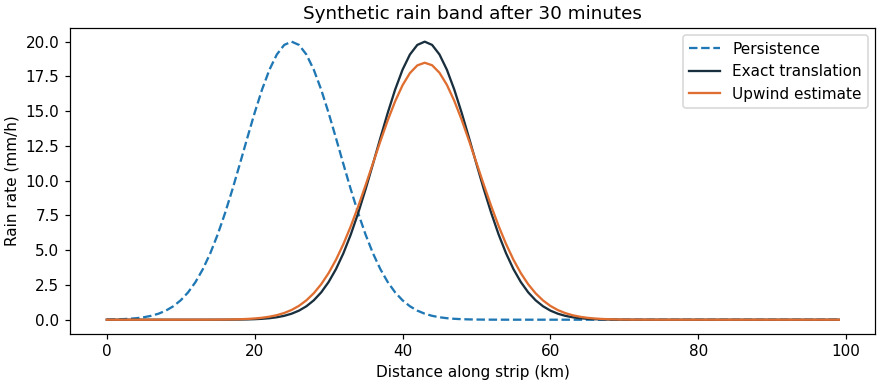

Persistence RMSE: 8.87 mm/h
Upwind RMSE: 0.45 mm/h
Exact peak: 20.00 mm/h. Upwind peak: 18.48 mm/h.


In [2]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.plot(x_m / 1000, start_rate, "--", label="Persistence")
ax.plot(x_m / 1000, reference, color="#192f3d", label="Exact translation")
ax.plot(x_m / 1000, correct_wind, color="#df6e30", label="Upwind estimate")
ax.set(xlabel="Distance along strip (km)", ylabel="Rain rate (mm/h)",
       title="Synthetic rain band after 30 minutes")
ax.legend()
plt.show()
print(f"Persistence RMSE: {rmse(start_rate, reference):.2f} mm/h")
print(f"Upwind RMSE: {rmse(correct_wind, reference):.2f} mm/h")
print(f"Exact peak: {reference.max():.2f} mm/h. Upwind peak: {correct_wind.max():.2f} mm/h.")

## Scenario 6 · The forecast wind points the wrong way

Keep the reference moving eastward. Run the model with a slower eastward wind and with a westward wind. Compare each error with persistence. Next, halve the cell spacing and the time step together. This preserves the Courant number and the 30-minute lead while giving the shape more cells. Compare the fine run with its exact reference on the fine grid. The two comparisons answer different questions: sensitivity to wind input and sensitivity to numerical resolution.

In [3]:
for wind_m_s in (5, -10):
    estimate = transport_periodic(start_rate, wind_m_s, 1000, 60, 30)
    print(f"Wind {wind_m_s:+3} m/s: RMSE {rmse(estimate, reference):.2f} mm/h")

fine_x_m = np.arange(0, 100000, 500)
fine_start = initial_band(fine_x_m)
fine_reference = initial_band(fine_x_m - 10 * lead_s)
fine_estimate = transport_periodic(fine_start, 10, 500, 30, 60)
print(f"Finer grid, same lead: RMSE {rmse(fine_estimate, fine_reference):.2f} mm/h")
np.testing.assert_allclose(fine_estimate.sum() * 500, fine_start.sum() * 500)
assert rmse(fine_estimate, fine_reference) < rmse(correct_wind, reference)
assert rmse(transport_periodic(start_rate, -10, 1000, 60, 30), reference) > rmse(start_rate, reference)

try:
    transport_periodic(start_rate, 10, 1000, 120, 15)
except ValueError as error:
    print(error)
else:
    raise AssertionError("The time step above the Courant limit should have been rejected.")

Wind  +5 m/s: RMSE 5.68 mm/h
Wind -10 m/s: RMSE 9.41 mm/h
Finer grid, same lead: RMSE 0.24 mm/h
Courant number 1.20 exceeds 1. Reduce the time step.


## Submit a forecast comparison

Record errors for persistence, correct wind, slow wind and reversed wind. Explain why an integral check and an error score answer different questions. Choose one condition that breaks the translation model, such as a shower forming between frames. Describe the additional observation you would need to test how often that condition occurs, then reuse Notebook 07's issue-time rule when selecting forecast inputs.